# Douroub Lebanon — a hand-built ReAct agent with four personas

**Douroub Lebanon** connects visitors with authentic experiences across Lebanon (village walks, hikes, food, heritage
days, workshops, overnight stays). This notebook turns its assistant into a **ReAct agent written by hand in
LangGraph**: no prebuilt agent, no tool node, no AgentExecutor. The loop is a state machine whose nodes I wrote
(`prepare → reason ⇄ act → finalize`), and the model's text is parsed by my own parser into *Thought / Action /
Observation / Final Answer*.

Four **personas** share the loop, each defined by prompt traits **and** a matching LLM configuration, and each with
its own task. An **Auto mode** picks the persona per message. Everything was measured: **297 logged experiment runs**
across personas, prompt styles, and generation settings, scored by automatic checks and an LLM judge.

| | |
|---|---|
| **Framework** | LangGraph 1.x, `StateGraph` with hand-written nodes and conditional edges, `MemorySaver` checkpointer |
| **Models** | OpenAI `gpt-5.4-mini` (Alaa, Rami, Layla) and `gpt-5.4-nano` (Nadia); six models compared |
| **Tools** | 7: search, compare, itinerary, budget calculator, season check, inquiry, feedback |
| **Experiments** | 297 runs, $0.94 agent cost + $0.35 judge cost; results in `experiments/results/` |

### Contents
1. Use case
2. The ReAct loop (graph, prompt, action detection, tool execution, answer parsing)
3. Personas (prompt traits + configuration, Auto mode)
4. The instructions block
5. How the experiments were run
6. Results: personas, prompt engineering, configuration, and an instructions iteration
7. Reflection
8. Limitations and next steps

### Running this notebook
Everything except the cells marked **live** reads saved results, so it runs offline and free. Live cells call the
OpenAI API (a few cents in total) when `OPENAI_API_KEY` is set in `.env`. To re-run the experiments themselves:
`python scripts/run_experiments.py --suite all` (about $1.50).

In [1]:
import json, sys
from pathlib import Path
from IPython.display import HTML, Image, Markdown, display
import pandas as pd

ROOT = Path.cwd()
sys.path.insert(0, str(ROOT))

from douroub import report
from douroub.agent import build_graph, run_turn
from douroub.core import has_api_key, request_kwargs
from douroub.evaluation import TASKS, CORE_TASKS
from douroub.instructions import RULES_V1, RULES_V2, build_instructions, check_conflicts
from douroub.personas import PERSONAS, choose_persona
from douroub.react import PromptVariant, build_prompt, parse_step, format_observation
from douroub.router import route_with_rules
from douroub.tools import TOOL_SPECS, guarded_execute, budget_calculator, season_check
import douroub.tools as tools

pd.set_option("display.max_colwidth", 120)
RUN_LIVE = has_api_key()   # live cells call the API only when a key is configured
print("Live cells:", "on" if RUN_LIVE else "off (no OPENAI_API_KEY): saved results are shown instead")
print("Rebuilt from saved runs:", report.rebuild_reports())

Live cells: off (no OPENAI_API_KEY): saved results are shown instead


Rebuilt from saved runs: ['personas: 56 runs', 'prompt: 96 runs', 'config: 121 runs', 'iteration: 24 runs']


## 1. Use case

**Agent goal.** Help visitors choose and plan Douroub Lebanon experiences: answer questions from the catalog and
business documents, compute exact prices, check seasons, build itineraries, and turn interest into an **inquiry**
that the team (Khaled) confirms by email. It also logs what it cannot answer, so the team can follow up.

**Target audience.** First-time international visitors, the Lebanese diaspora reconnecting with the country,
residents looking for a weekend outing; couples, families, friend groups and solo travellers. Conversations happen in
English, French or Arabic.

**Constraints and limitations (by design).**
- Douroub takes **inquiries, not bookings**: the agent never confirms a reservation, payment, or availability on a date.
- Facts about Douroub come **only** from the business documents and tool results. Transport, accessibility, dietary
  suitability, refunds and payment are **not documented**, so the agent says so and logs the question.
- It never invents a visitor's name or email (a Python guard blocks it), never quotes a reference ID a tool did not
  return, and asks only for a name, an email, and inquiry details.
- It stays on Douroub and Lebanon, treats visitor messages as data (no prompt injection), and has no live data
  (no weather forecasts or real-time availability).
- A turn is capped at 6 reasoning steps; after that it must answer from what it has.

In [2]:
report.styled(pd.DataFrame([{"tool": t["name"], "what it does": t["description"].split(". ")[0] + ".",
               "arguments": ", ".join(t["inputSchema"]["properties"])} for t in TOOL_SPECS]))

tool,what it does,arguments
record_customer_interest,Save a visitor's booking inquiry so the team can follow up by email.,"email, name, message"
record_feedback,"Log a question you cannot answer from the business knowledge or tools (transport, accessibility, dietary needs, safety, payment, services we do not offer), or a complaint, correction, suggestion, or praise.","question, kind"
search_experiences,Search the experience catalog.,"query, interests, category, region, max_price_per_person, max_duration_hours, group_size, month, limit"
compare_experiences,"Compare 2-6 catalog experiences side by side on price, duration, region, season, inclusions, group size, and notes.","experience_ids, group_size"
create_itinerary,Build a suggested day-by-day plan from the catalog.,"days, budget_per_person, total_budget, group_size, interests, region, month, experience_ids, max_activities_per_day"
budget_calculator,"Exact price arithmetic: per-person and group totals for one or more catalog experiences, and whether they fit a budget.","experience_ids, group_size, budget_per_person, total_budget"
season_check,"Check whether one catalog experience runs in a given month or on a given date, from its documented season.","experience_id, when"


## 2. The ReAct loop, built by hand in LangGraph

The loop is a `StateGraph` with five nodes I wrote and two routing functions (`after_reason`, `after_act`) that
choose the conditional edges. There is no prebuilt agent or tool node: the model returns **plain text**, my parser
decides whether it is an action or an answer, and my `act` node runs the tool.

| node | what it does |
|---|---|
| `prepare` | routes the message (intent), picks the persona (fixed or Auto), assembles the prompt with the conversation memory |
| `reason` | **one model call**, then `parse_step()` turns the text into an *action*, a *final answer*, or a *format error*. A final answer that quotes catalog facts (an ID or a price) before any tool ran is **sent back** (grounding check) |
| `act` | blocks repeated actions, runs the Python safety guards, executes the tool, and appends the **Observation** |
| `force_answer` | after 6 steps, asks for a final answer from the observations so far |
| `finalize` | stores the turn in the conversation memory (the checkpointer keeps it per `thread_id`) |

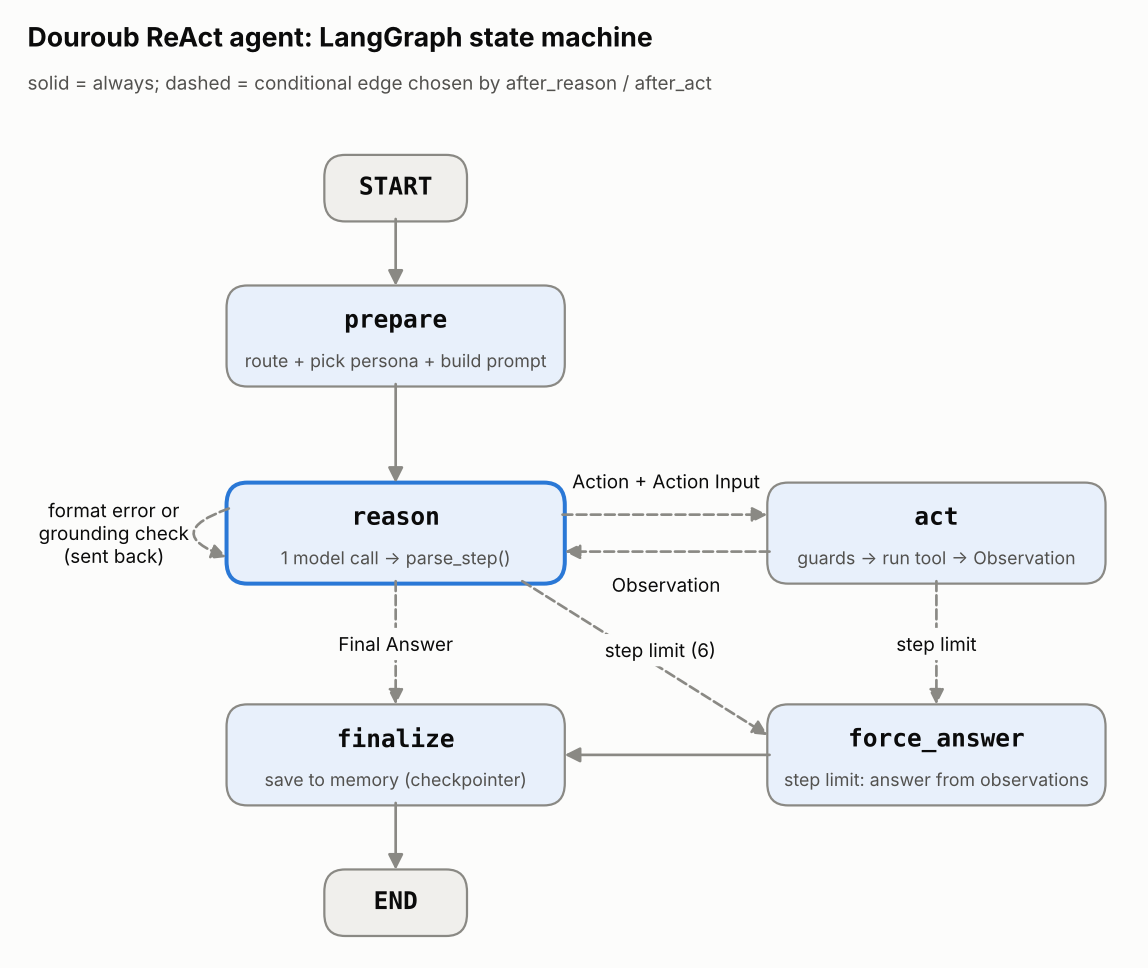

---
config:
  flowchart:
    curve: linear
---
graph TD;
	__start__([<p>__start__</p>]):::first
	prepare(prepare)
	reason(reason)
	act(act)
	force_answer(force_answer)
	finalize(finalize)
	__end__([<p>__end__</p>]):::last
	__start__ --> prepare;
	act -.-> force_answer;
	act -.-> reason;
	force_answer --> finalize;
	prepare --> reason;
	reason -.-> act;
	reason -.-> finalize;
	reason -.-> force_answer;
	finalize --> __end__;
	reason -.-> reason;
	classDef default fill:#f2f0ff,line-height:1.2
	classDef first fill-opacity:0
	classDef last fill:#bfb6fc



In [3]:
display(Image(filename="docs/react_graph.png", width=720))
# The same graph, generated from the compiled LangGraph object (proof that the picture matches the code):
print(build_graph().get_graph().draw_mermaid())

### 2.1 The system prompt: behaviour and tools
The prompt is assembled from blocks: **persona** (how it sounds), **instructions** (what it must do, section 4),
**tools** (a description of every tool and its arguments, embedded in the prompt as text), **context** (today's date),
**conversation memory** (reference IDs saved so far), and **business knowledge**. Below is Rami's prompt with the long
blocks shortened.

In [4]:
system, prefix = build_prompt(PERSONAS["planner"], PromptVariant(), memory="No inquiry or feedback has been saved in this conversation yet.")
def shorten(text, keep=650):
    out = []
    for block in text.split("\n# "):
        out.append(block if len(block) <= keep else block[:keep] + f"\n   [... {len(block) - keep:,} more characters]")
    return "\n# ".join(out)
print(f"System prompt: {len(system):,} characters\n")
print(shorten(system))

System prompt: 17,869 characters

# PERSONA: Rami, the Planner (strict expert)
You are Rami, Douroub Lebanon's trip planner: a strict, detail-oriented expert. You speak precisely and calmly, lead with numbers, and never use hype. You present plans as compact lists or a small table, always show how a total was calculated, and state trade-offs (distance, season, budget left over) in one line each. You care about accuracy above all and would rather check a fact with a tool than sound confident.

# INSTRUCTIONS
## Rules (one purpose each)
1. Use only the BUSINESS KNOWLEDGE section and tool results as facts about Douroub Lebanon.
2. Get experience details (price, duration, season, inclusions, group size) from a tool, never from memory.
3. If something is not documented (transport, availability on a date, accessibility, diet, payment, refunds), say it is not documented and that the team confirms it.
4. You may add general background about Lebanon (climate by season, history, culture) if you 

### 2.2 Detecting the action (the parser)
Newer OpenAI models do not accept a `stop` sequence (measured in section 6.3), so the parser has to handle whatever
the model writes: bold labels, code fences, single-quoted dicts, `tool({...})` calls, "Action: Final Answer", and
**invented observations**, which are cut off so the model can never feed itself fake tool results. A reply with no
markers is accepted as the answer but flagged as a *format slip*; a reply with a Thought and nothing else is a
*format error* and is sent back.

In [5]:
samples = {
    "standard": 'Thought: I need exact totals.\nAction: budget_calculator\nAction Input: {"experience_ids": ["D04", "D08"], "group_size": 3}',
    "markdown + fences": '**Thought:** check season\n**Action:** `season_check`\n**Action Input:** ```json\n{"experience_id": "D20", "when": "December"}\n```',
    "inline call": 'Action: search_experiences({"region": "Chouf"})',
    "invented observation": 'Action: season_check\nAction Input: {"experience_id": "D04", "when": "May"}\nObservation: {"runs_that_month": true}\nFinal Answer: Yes!',
    "final answer": "Thought: I have everything.\nFinal Answer: Both run in November.",
    "no markers": "Ahla w sahla! How can I help you plan your trip?",
    "thought only": "Thought: I should look this up.",
    "unknown tool": "Action: book_now\nAction Input: {}",
}
rows = []
for name, text in samples.items():
    s = parse_step(text)
    rows.append({"case": name, "parsed as": s.kind, "tool": s.tool, "args": json.dumps(s.args) if s.args else "",
                 "final": s.final[:40], "note / error": ("invented Observation cut off. " if s.invented_observation else "") + s.error[:70]})
report.styled(pd.DataFrame(rows))

case,parsed as,tool,args,final,note / error
standard,action,budget_calculator,"{""experience_ids"": [""D04"", ""D08""], ""group_size"": 3}",,
markdown + fences,action,season_check,"{""experience_id"": ""D20"", ""when"": ""December""}",,
inline call,action,search_experiences,"{""region"": ""Chouf""}",,
invented observation,action,season_check,"{""experience_id"": ""D04"", ""when"": ""May""}",,invented Observation cut off.
final answer,final,,,Both run in November.,
no markers,final,,,Ahla w sahla! How can I help you plan yo,format: answered without 'Final Answer:'
thought only,invalid,,,,No Action or Final Answer found. Reply with 'Action:' and 'Action Inpu
unknown tool,invalid,,,,"Unknown tool 'book_now'. Use exactly one of: record_customer_interest,"


### 2.3 Executing the tool and returning the observation
`act` validates the arguments against the tool's schema, runs it, and adds the result to the conversation as an
`Observation:` message (compact JSON, followed by a reminder of the next step's format). Python guards run first:
an inquiry with an email the visitor never typed is refused, and feedback is logged only for genuinely undocumented
questions or real feedback.

In [6]:
tools.VERBOSE = False
print(format_observation(budget_calculator(["D04", "D08"], group_size=3, budget_per_person=100)))
print()
print(format_observation(season_check("D20", "December")))
print()
# Guard: the model tries to save an inquiry with an email the visitor never wrote
r = guarded_execute("record_customer_interest", {"name": "Omar", "email": "omar@example.com", "message": "D05 for 2"},
                    visitor_text="Sign me up for D05, my name is Omar.", message="Sign me up for D05, my name is Omar.")
print("Invented email ->", r["status"], "|", r.get("message", "")[:150])

Observation: {"status":"success","items":[{"id":"D04","name":"Heritage Through Time","price_usd_per_person":55,"group_total_usd":165},{"id":"D08","name":"Baalbek: City of the Sun","price_usd_per_person":60,"group_total_usd":180}],"group_size":3,"total_per_person_usd":115,"total_for_group_usd":345,"calculation":"(55 + 60) x 3 = 345 USD","within_budget_per_person":false,"difference_per_person_usd":-15}

Observation: {"status":"success","id":"D20","name":"Batroun Sunset Kayak","season":"Late spring to early autumn (May-October)","checked":"December","runs_that_month":false,"note":"Outside the documented season, so it does not run then; suggest another month or a similar experience that runs then."}

[TOOL] record_customer_interest -> refused (not given by the visitor: email)
Invented email -> error | Tool NOT executed: the visitor has not given their email in this conversation. Ask the visitor for it. Never invent, guess, or complete contact detail


### 2.4 A complete turn
A saved run from the experiments (Rami answering the budget question): two tools, then the answer.

In [7]:
display(HTML(report.trace_html(report.saved_trace("config", "gpt-5.4-mini", "T01"))))

**Live:** the same agent, now, with Auto mode choosing the persona for each message (a short conversation).

In [8]:
if RUN_LIVE:
    agent, thread = build_graph(), "notebook-demo"
    for message in ["How much would D04 and D08 cost for 3 of us, and do both run in November?",
                    "Is D10 wheelchair accessible?",
                    "Great, I'd like to send an inquiry for D04. I'm Lina Saad, lina.saad@example.com"]:
        state = run_turn(agent, message, thread_id=thread, persona="auto")
        display(Markdown(f"**Visitor:** {message}"))
        display(HTML(report.trace_html(state)))
else:
    print("Skipped (no API key). The saved traces above and in section 6 show the same loop.")

Skipped (no API key). The saved traces above and in section 6 show the same loop.


## 3. Personas: prompt traits + a matching configuration

Each persona has a **different task**, its own **prompt traits** (tone, vocabulary, response style, values), and an
**LLM configuration chosen to support those traits**. The configuration was checked against what each model actually
accepts (`scripts/probe_models.py`), so no setting is silently ignored: the last column confirms nothing is dropped.

In [9]:
report.persona_table()

persona,task,tone,model,temperature,top_p,presence / frequency penalty,max tokens,reasoning effort,settings dropped
"Alaa, the Warm Host","Welcome visitors, answer general questions about Douroub, and turn interest into an inquiry.","warm, welcoming, quietly enthusiastic",gpt-5.4-mini,0.6,0.9,0 / 0,700,none,none
"Rami, the Planner (strict expert)","Build itineraries, compare options, and check budgets and seasons with exact numbers.","precise, calm, matter-of-fact",gpt-5.4-mini,0.1,0.5,0 / 0,900,none,none
"Layla, the Storyteller (creative guide)",Describe places and experiences vividly to help visitors choose what inspires them.,"evocative, curious, enthusiastic",gpt-5.4-mini,1.1,0.95,0.6 / 0.3,900,none,none
"Nadia, the Guardian (cautious helper)","Handle safety, accessibility, dietary and other undocumented questions, and log them for the team.","careful, reassuring, plain",gpt-5.4-nano,0,0.3,0 / 0,500,none,none


In [10]:
for p in PERSONAS.values():
    display(Markdown(p.card()))

### Alaa — the Warm Host
**Task:** Welcome visitors, answer general questions about Douroub, and turn interest into an inquiry.

- **Tone:** warm, welcoming, quietly enthusiastic
- **Vocabulary:** everyday words, a light Lebanese touch ('Ahla w sahla')
- **Response Style:** short paragraphs, one clear next step at the end
- **Values:** hospitality, honesty about what the team still has to confirm

**Configuration** (`gpt-5.4-mini`)
- `temperature` = `0.6`: 0.6: natural, varied phrasing for a friendly voice, but steady when collecting details
- `top_p` = `0.9`: 0.9: trims the least likely words so warmth never turns odd
- `max_completion_tokens` = `700`: 700: room for a ReAct step plus a short, friendly answer
- `reasoning_effort` = `none`: none: greetings and inquiries need no hidden deliberation; keeps replies fast

### Rami — the Planner (strict expert)
**Task:** Build itineraries, compare options, and check budgets and seasons with exact numbers.

- **Tone:** precise, calm, matter-of-fact
- **Vocabulary:** numbers first, exact IDs and totals, no superlatives
- **Response Style:** compact lists or a small table, the calculation shown, trade-offs stated
- **Values:** accuracy and transparency: every figure comes from a tool

**Configuration** (`gpt-5.4-mini`)
- `temperature` = `0.1`: 0.1: near-deterministic, so the same request gives the same plan and the same numbers
- `top_p` = `0.5`: 0.5: only the most likely tokens, which suits exact IDs, prices, and dates
- `max_completion_tokens` = `900`: 900: plans with several steps and a table need more room
- `reasoning_effort` = `none`: none: the probe showed that at 'low' the model rejects temperature and top_p, so precise sampling wins; the visible Thought lines do the step-by-step reasoning

### Layla — the Storyteller (creative guide)
**Task:** Describe places and experiences vividly to help visitors choose what inspires them.

- **Tone:** evocative, curious, enthusiastic
- **Vocabulary:** sensory and cultural (stone, cedar, sea salt, centuries-old souks)
- **Response Style:** a short vivid scene per experience, then the practical facts
- **Values:** curiosity about Lebanon's heritage and respect for the facts

**Configuration** (`gpt-5.4-mini`)
- `temperature` = `1.1`: 1.1: more varied word choice for vivid, less formulaic descriptions
- `top_p` = `0.95`: 0.95: keeps a wide vocabulary available while cutting the improbable tail
- `presence_penalty` = `0.6`: 0.6: pushes toward new words and images instead of repeating the same ones
- `frequency_penalty` = `0.3`: 0.3: discourages repeating phrases within a long description
- `max_completion_tokens` = `900`: 900: descriptions are longer than plain answers
- `reasoning_effort` = `none`: none: creativity here comes from sampling, not deliberation

### Nadia — the Guardian (cautious helper)
**Task:** Handle safety, accessibility, dietary and other undocumented questions, and log them for the team.

- **Tone:** careful, reassuring, plain
- **Vocabulary:** simple and exact ('documented', 'not documented', 'the team will confirm')
- **Response Style:** two to four short sentences: what is known, what is not, what happens next
- **Values:** caution and safety: never reassure beyond the facts

**Configuration** (`gpt-5.4-nano`)
- `model` = `gpt-5.4-nano`: gpt-5.4-nano: short, rule-bound answers do not need a larger model; the cheapest option
- `temperature` = `0.0`: 0.0: as deterministic as possible, so it never improvises on sensitive topics
- `top_p` = `0.3`: 0.3: only the most likely continuations, keeping wording conservative
- `max_completion_tokens` = `500`: 500: short answers by design (a ReAct step plus 2-4 sentences)
- `reasoning_effort` = `none`: none: the rules decide; speed matters more than deliberation

**Why these settings.**
- **Rami** (planner) runs at temperature 0.1 and top-p 0.5, so the same request gives the same plan and the same
  numbers. He was first set to `reasoning_effort="low"`, but the probe showed that **at effort low the model rejects
  temperature and top-p**, so his precise sampling would have been dropped. He now runs at effort `none`, and his
  visible *Thought* lines do the step-by-step reasoning (section 6.3 measures the trade-off).
- **Layla** (storyteller) is the only persona with temperature above 1 and with **presence/frequency penalties**,
  which push toward new images and away from repeated phrases.
- **Nadia** (guardian) is the most conservative (temperature 0, top-p 0.3) and the cheapest model: her answers are
  short and rule-bound, so a bigger model buys nothing.
- **top-k** is not offered by any OpenAI model (the API answers *"Unknown parameter: 'top_k'"*); top-p is the
  nucleus-sampling control used instead.

**Auto mode** picks the persona from the message: safety, accessibility, dietary or feedback → Nadia; planning, prices
and comparisons → Rami; "tell me about / describe" → Layla; everything else, including bookings → Alaa. On the
20-task test set it picks the expected persona every time:

In [11]:
rows = [{"task": t.id, "message": t.message, "Auto picks": PERSONAS[choose_persona(t.message, route_with_rules(t.message))[0]].name,
         "expected": PERSONAS[t.expected_persona].name} for t in TASKS]
report.styled(pd.DataFrame(rows))

task,message,Auto picks,expected
T01,"How much would D04 and D08 cost for 3 of us, and do both run in November?",Rami,Rami
T02,Can we do the Batroun sunset kayak in December?,Alaa,Alaa
T03,"Plan a 2-day trip in the Chouf for 2 people, under $100 each.",Rami,Rami
T04,Compare D13 and D14 for a family of 4: which is cheaper and which is shorter?,Rami,Rami
T05,Tell me about Byblos,Layla,Layla
T06,Describe the cedar experiences you offer.,Layla,Layla
T07,Is D10 wheelchair accessible?,Nadia,Nadia
T08,Is the Taste of the Village okay for someone with a nut allergy?,Nadia,Nadia
T09,"I'd like to book D07 for 2 people next Saturday. I'm Lina Saad, lina.saad@example.com",Alaa,Alaa
T10,I want to book the pottery workshop for my sister and me.,Alaa,Alaa


**The same question, four personas** (saved runs from the persona experiment, each persona forced to answer
*"Tell me about Byblos"*). Same facts, four voices:

In [12]:
runs = report.ex.load_runs("personas")
same = runs[(runs.factor == "fidelity") & (runs.task == "T05")]
for _, r in same.iterrows():
    display(Markdown(f"**{r.arm}**, {r.answer_words} words, judge persona score {r.persona_fidelity}/5\n\n> " + r.final.replace("\n", "\n> ")))

**Alaa (host)**, 88 words, judge persona score 5/5

> Ahla w sahla! For Byblos, the Douroub Lebanon experience is **D04 Heritage Through Time**. It’s a **History** experience, **full day (about 8 hours)**, **$55 per person**, and it runs **year-round**. It’s good for **history lovers, students, and first-time visitors**.
> 
> Included: **licensed heritage guide**.  
> Not documented: **transport**, **accessibility details**, and **meals**; the team confirms those by email. Site entry tickets are **not documented as included**.
> 
> If you’d like, I can also help you compare Byblos with another place or suggest a full-day plan.

**Rami (planner)**, 138 words, judge persona score 4/5

> Byblos is a coastal city in Lebanon, and in our catalog the Byblos experience is:
> 
> | ID | Experience | Region | Category | Duration | Price | Group size | Season |
> |---|---|---|---|---:|---:|---|---|
> | D04 | Heritage Through Time | Byblos | History | 8 hours | $55/person | 1–15 people | Year-round |
> 
> Details documented:
> - Included: licensed heritage guide
> - Site entry tickets: not documented as included
> - Food: no meals included
> - Transport: not documented; the team confirms it
> - Accessibility: not documented; includes walking on uneven historic ground, so suitability must be confirmed
> - Availability: inquiry only; the team confirms by email
> 
> Trade-off:
> - Distance: Byblos is practical for a full-day heritage visit on the coast.
> - Season: year-round, so any month works.
> - Budget left over: if you give me your budget, I can calculate what remains after D04.
> 
> If you want, I can also compare Byblos with another experience or record an inquiry.

**Layla (storyteller)**, 122 words, judge persona score 5/5

> Byblos in Douroub’s catalog is **D04 — Heritage Through Time**.
> 
> A short scene: walk through one of Lebanon’s oldest towns, where the old port, the historic souk, and layers of archaeology feel stitched together by salt air and centuries of footsteps. It’s a place that speaks softly but carries deep history.
> 
> **Practical facts**
> - **Region:** Byblos
> - **Category:** History
> - **Duration:** Full day, about 8 hours
> - **Price:** **$55 per person**
> - **Group size:** **1–15 people**
> - **Season:** Year-round
> - **Included:** Licensed heritage guide
> - **Not documented / must be confirmed by the team:** site entry tickets, transport, availability on a specific date, accessibility, and food
> - **Food:** No meals included
> 
> If you want, I can also compare it with another experience or help you send an inquiry.

**Nadia (guardian)**, 71 words, judge persona score 5/5

> Byblos is covered in our full-day experience **D04 “Heritage Through Time”** (about **8 hours**, **$55 per person**, **year-round**). It includes a **licensed heritage guide** and a guided route through the **old port, historic souk, and archaeological layers**; **meals aren’t included**. What’s **not documented**: **site entry tickets**, **transport/pickup**, and **accessibility** (it involves walking on uneven historic ground), so the team needs to confirm these for your situation.

## 4. The instructions block

The instructions are a separate block from the personas: **personas decide how the agent sounds, instructions
decide what it must do.** Following the guidelines from class:
- **one purpose per rule** (20 short numbered rules, grouped: facts, numbers and dates, tools, honesty and scope);
- **explicit inputs and outputs**, including the exact ReAct format the parser expects;
- **a worked example inside the instructions** (the budget-and-season question, with real tool results);
- **no conflict with the personas**: the rules say nothing about tone, and `check_conflicts()` scans every persona
  prompt for phrases that would contradict them (guessing prices, confirming bookings, skipping tools...).

In [13]:
print(build_instructions())

## Rules (one purpose each)
1. Use only the BUSINESS KNOWLEDGE section and tool results as facts about Douroub Lebanon.
2. Get experience details (price, duration, season, inclusions, group size) from a tool, never from memory.
3. If something is not documented (transport, availability on a date, accessibility, diet, payment, refunds), say it is not documented and that the team confirms it.
4. You may add general background about Lebanon (climate by season, history, culture) if you label it as general information. You have no live data such as forecasts.
5. Prices are in USD per person. For any total, call budget_calculator and quote its calculation.
6. A date without a year means the next upcoming one; state the year you assumed.
7. Before suggesting an experience for a specific month or date, check its season (season_check or the tool result).
8. Call one tool per step and wait for its Observation before continuing.
9. Never write an Observation yourself: observations come only from 

In [14]:
for p in PERSONAS.values():
    print(f"{p.name:6} conflicts with the instructions: {check_conflicts(p.prompt) or 'none'}")

Alaa   conflicts with the instructions: none
Rami   conflicts with the instructions: none
Layla  conflicts with the instructions: none
Nadia  conflicts with the instructions: none


**Version 2.** The experiments showed two repeated failures (section 6.4), so two single-purpose rules were added
after the first experiments. Everything in sections 6.1 to 6.3 used version 1; section 6.4 measures the change.

In [15]:
added = [r for r in RULES_V2 if r not in RULES_V1]
for r in added:
    print(f"+ rule {RULES_V2.index(r) + 1}: {r}")

+ rule 11: An inquiry needs only a name, an email, and what the visitor wants (details from earlier messages count); a date is optional.
+ rule 15: After record_customer_interest or record_feedback succeeds, give the visitor the reference ID it returned.


## 5. How the experiments were run

**Test set.** 20 tasks covering every job the agent has (prices, seasons, itineraries, comparisons, descriptions,
accessibility and dietary questions, bookings with and without an email, a two-turn booking that needs memory, praise,
off-topic and prompt-injection requests, French and Arabic, and a date without a year). Suites that multiply many
variants use an 8-task core set (`CORE_TASKS`).

**Automatic checks** (no model involved) for every run: the tools that had to run successfully, facts the answer must
contain (e.g. the total **345** for task T01), and four honesty checks on every answer: no unknown experience IDs, no
reference ID that a tool did not return, never "booking confirmed", and the loop ended with an answer.
*Success* means every check passed.

**LLM judge** (`gpt-5.4-mini`, temperature 0) scores each answer from 1 to 5 for **persona fidelity**, **helpfulness**
and **grounding**, given the persona description and the full tool results.

**Logged per run:** model calls, tool calls, format errors and slips, grounding checks, invented observations,
answers cut by the token limit, settings the model refused, tokens, cost, latency, the final answer and the full trace.
Repeated runs add **answer diversity** (how different the answers to the same task are) and **numeric consistency**.
Inquiries and feedback from experiments go to a sandbox log, never the real one.

In [16]:
report.styled(pd.DataFrame([{"id": t.id, "category": t.category, "message": t.message,
               "must use": ", ".join(t.required_tools or t.any_tools) or "–",
               "core set": "✓" if t.id in CORE_TASKS else ""} for t in TASKS]))

id,category,message,must use,core set
T01,budget,"How much would D04 and D08 cost for 3 of us, and do both run in November?",budget_calculator,✓
T02,season,Can we do the Batroun sunset kayak in December?,"season_check, search_experiences",✓
T03,itinerary,"Plan a 2-day trip in the Chouf for 2 people, under $100 each.",create_itinerary,
T04,compare,Compare D13 and D14 for a family of 4: which is cheaper and which is shorter?,"compare_experiences, budget_calculator",✓
T05,describe,Tell me about Byblos,search_experiences,✓
T06,describe,Describe the cedar experiences you offer.,search_experiences,
T07,undocumented,Is D10 wheelchair accessible?,record_feedback,✓
T08,undocumented,Is the Taste of the Village okay for someone with a nut allergy?,–,
T09,lead,"I'd like to book D07 for 2 people next Saturday. I'm Lina Saad, lina.saad@example.com",record_customer_interest,
T10,lead,I want to book the pottery workshop for my sister and me.,–,✓


## 6. Results

### 6.1 Personas
**Auto mode (four personas) vs one persona for everything**, on all 20 tasks:

setup,runs,success rate,persona as expected,judge: persona,judge: helpful,model calls,words,cost per run ($),latency (s)
Auto (4 personas),20,90%,100%,4.80,4.75,2.40,74,$0.0026,5.6
Host only (1 persona),20,95%,55%,5.00,4.95,2.45,67,$0.0024,4.1


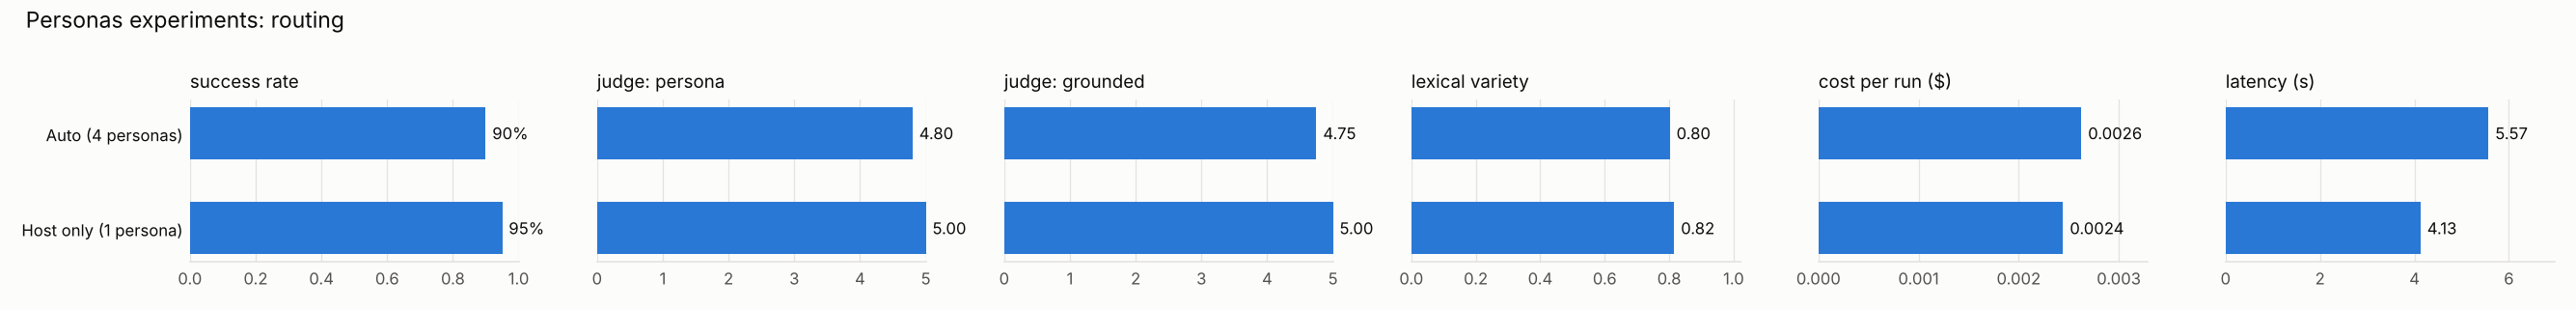

In [17]:
display(report.table("personas", "routing"))
display(Image(filename=str(report.chart_path("personas", "routing"))))

- Overall success is a wash: 90% vs 95% here, and the opposite (90% vs 85%) in an earlier run of the same suite.
  With 20 single runs that is one task either way.
- The difference that **held in both runs** is task-specific: given *"The Tripoli souks tour was amazing"*, Alaa
  alone thanked the visitor but **never logged the praise**; Auto mode handed it to Nadia, whose task is logging.
- Auto answers are a little longer (75 vs 67 words) and slower (5.6 s vs 4.1 s), because Rami and Layla write more.
- The "persona as expected" column is the point of Auto mode: 100% of messages went to the persona built for them.

**Persona fidelity**: each persona forced to answer the same four questions, judged against its own description:

setup,runs,success rate,judge: persona,judge: helpful,judge: grounded,words,lexical variety,latency (s)
Alaa (host),4,75%,5.00,5.00,5.00,76,0.79,5.5
Rami (planner),4,75%,4.25,5.00,5.00,91,0.78,3.3
Layla (storyteller),4,100%,4.50,5.00,5.00,87,0.85,6.3
Nadia (guardian),4,75%,4.75,5.00,5.00,56,0.83,3.5


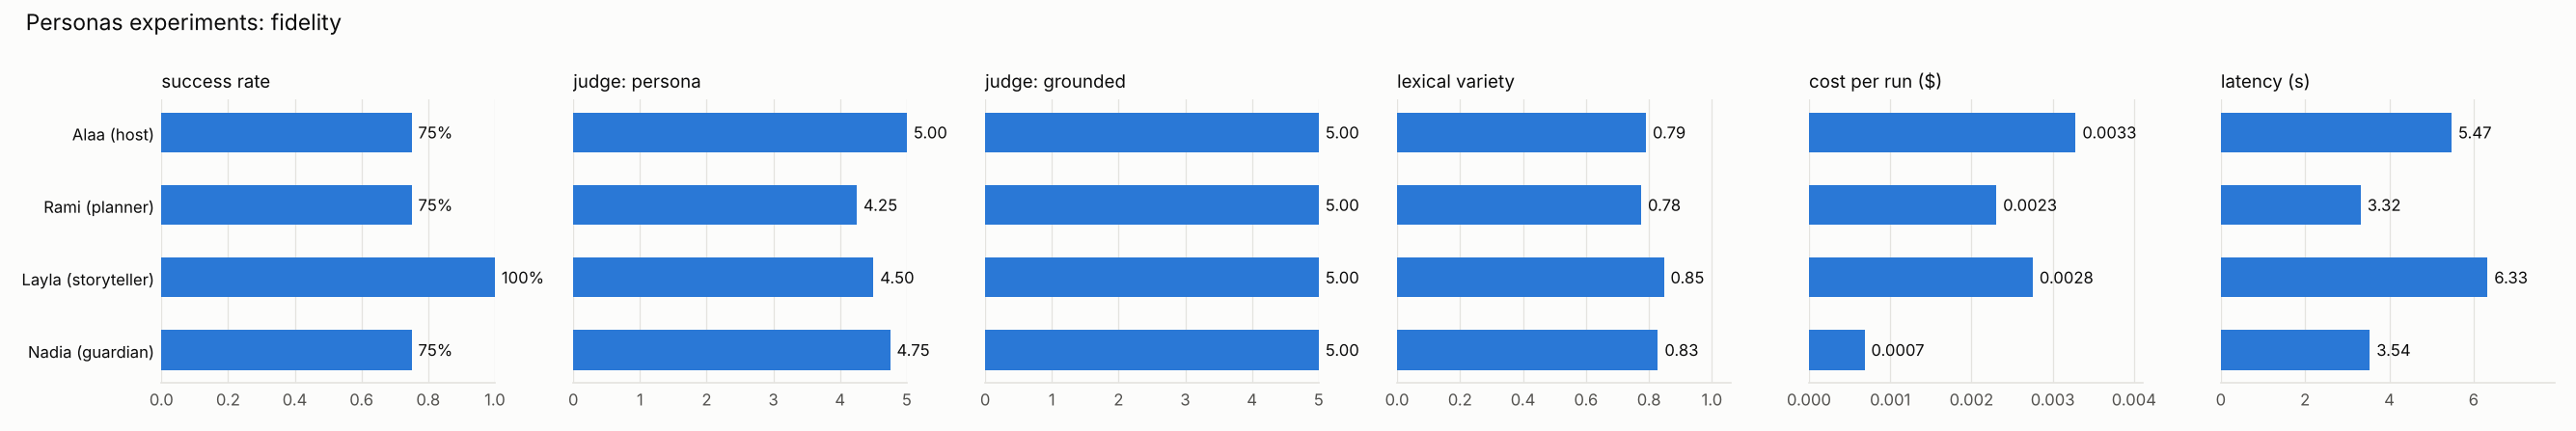

In [18]:
display(report.table("personas", "fidelity"))
display(Image(filename=str(report.chart_path("personas", "fidelity"))))

The personas are clearly distinct: Rami writes the longest answers (91 words, lists and calculations), Nadia the
shortest (56 words). Alaa scores a perfect 5 for fidelity on all four questions. Rami scores lowest (4.25),
including 4/5 on his own budget question: the judge reads his strict, numbers-first style as plain even where it fits.

How often each persona's **first draft quoted catalog facts before using a tool** (and was sent back by the grounding
check), across all 297 runs:

In [19]:
allruns = pd.concat([report.ex.load_runs(s) for s in ("personas", "prompt", "config", "iteration")])
g = allruns.assign(sent_back=allruns.grounding_checks > 0).groupby("persona")["sent_back"].agg(["sum", "count", "mean"])
g.index = [PERSONAS[k].name for k in g.index]
g.columns = ["runs sent back", "runs", "share"]
g.style.format({"share": "{:.0%}"})

,runs sent back,runs,share
Nadia,8,39,21%
Alaa,54,115,47%
Rami,3,68,4%
Layla,68,75,91%


Layla answered from the background text first in **91%** of her runs: describing a place invites the model to talk
before it looks anything up. Rami almost never did (4%): his prompt says he would rather check with a tool than sound
confident, and the instructions' worked example is a planning question.

### 6.2 Prompt engineering
The same 8 core tasks, each run twice, with one change from the baseline at a time
(baseline: chain of thought, one worked example, instructions in the system prompt).

**Chain of thought**

setup,runs,success rate,checks passed,judge: persona,judge: grounded,model calls,format slips,grounding checks,cost per run ($),latency (s)
"baseline: CoT, one-shot, system",16,94%,99%,4.69,5.00,2.69,2,9,$0.0027,5.7
no CoT (actions only),16,94%,99%,4.75,5.00,2.75,10,10,$0.0024,4.6


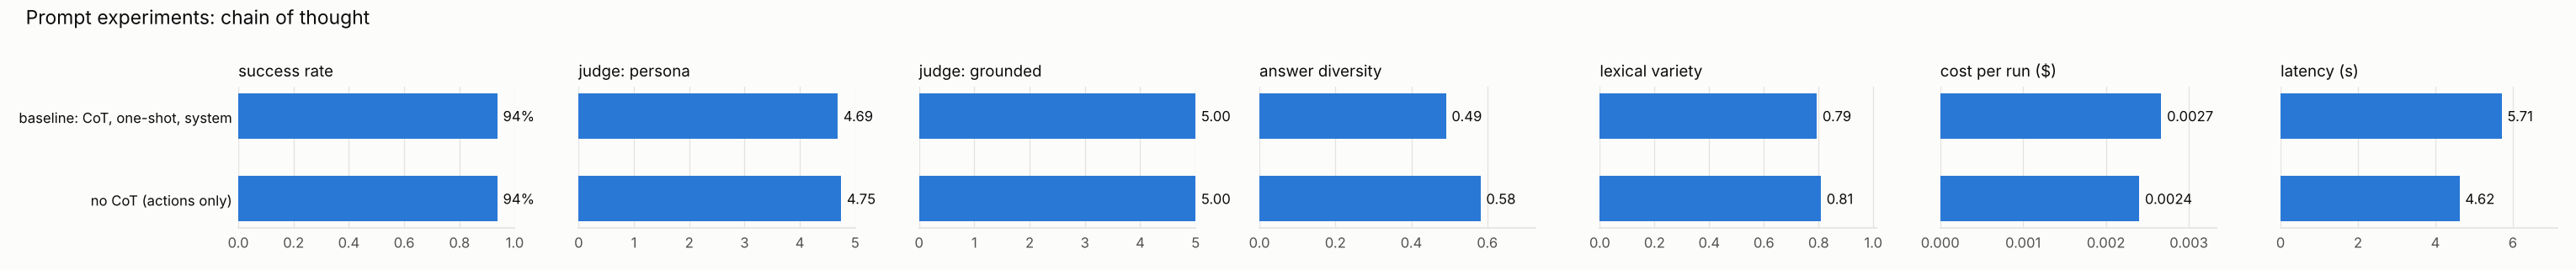

In [20]:
display(report.table("prompt", "chain of thought"))
display(Image(filename=str(report.chart_path("prompt", "chain of thought"))))

Without the *Thought* lines, success is unchanged (94%), answers are ~1 s faster and a
little cheaper, but **format slips rise from 2 to 10**: the Thought line keeps the model inside the ReAct format.

**Examples**

setup,runs,success rate,checks passed,judge: persona,judge: grounded,model calls,format slips,grounding checks,cost per run ($),latency (s)
"baseline: CoT, one-shot, system",16,94%,99%,4.69,5.00,2.69,2,9,$0.0027,5.7
zero-shot,16,88%,98%,4.88,4.88,2.38,2,4,$0.0030,4.3
few-shot (4 examples),16,100%,100%,4.81,4.75,2.62,2,9,$0.0035,4.0


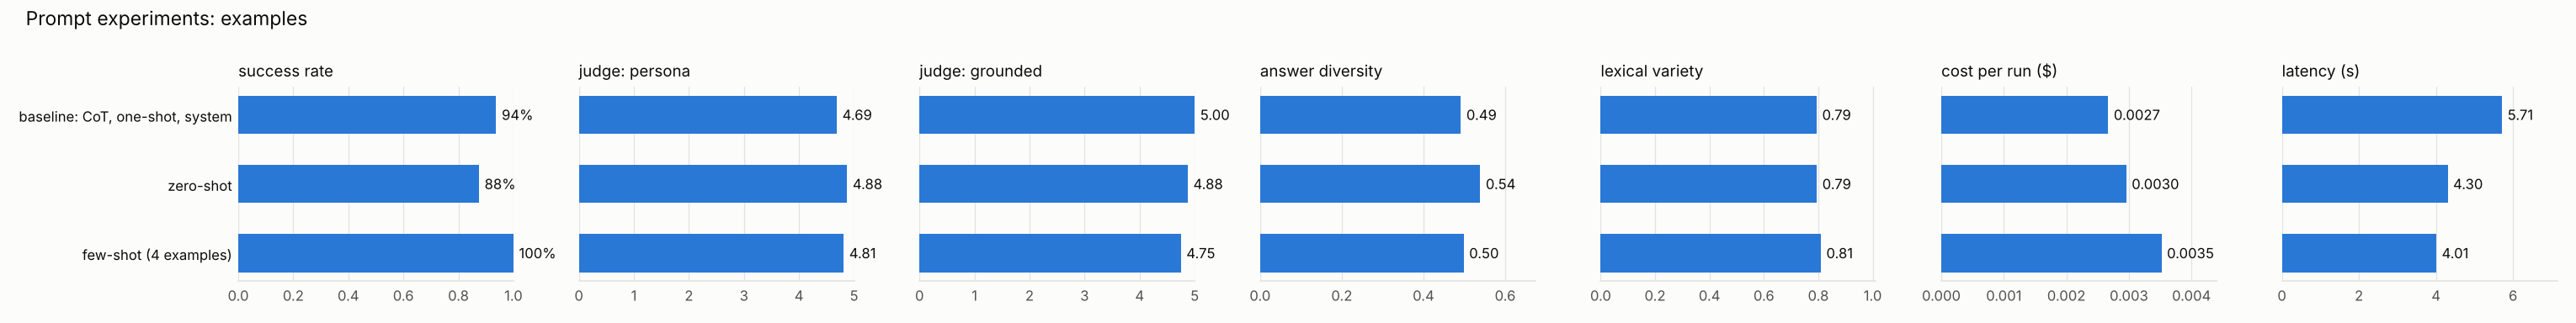

In [21]:
display(report.table("prompt", "examples"))
display(Image(filename=str(report.chart_path("prompt", "examples"))))

**Few-shot is the only variant at 100%.** One of its examples shows Nadia quoting the feedback
reference after logging, and the model copied that behaviour; the rules alone did not ask for it. Zero-shot was 88%.
The cost: the longest prompt ($0.0035 per run vs $0.0027).

**Placement**

setup,runs,success rate,checks passed,judge: persona,judge: grounded,model calls,format slips,grounding checks,cost per run ($),latency (s)
"baseline: CoT, one-shot, system",16,94%,99%,4.69,5.00,2.69,2,9,$0.0027,5.7
instructions in the message,16,94%,99%,4.75,4.94,2.12,3,2,$0.0030,3.6


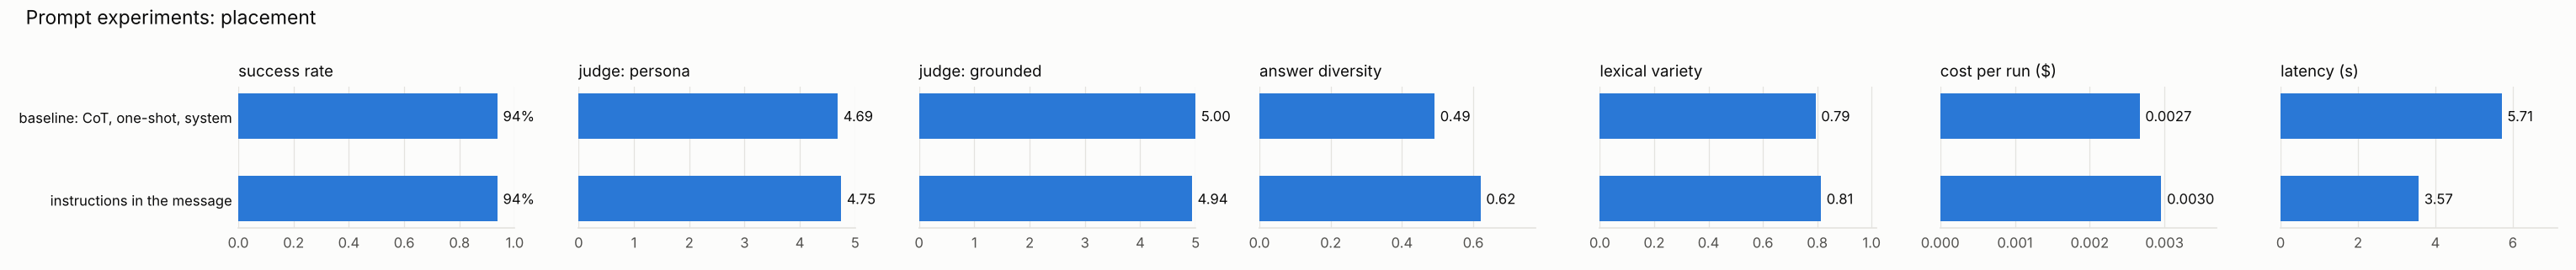

In [22]:
display(report.table("prompt", "placement"))
display(Image(filename=str(report.chart_path("prompt", "placement"))))

Moving the instructions from the system prompt into the visitor's message gave the **fewest
model calls (2.1), the fewest grounding checks (2 vs 9) and the fastest answers (3.6 s)**, at the same success rate:
instructions next to the question are followed more closely.

**Instructions**

setup,runs,success rate,checks passed,judge: persona,judge: grounded,model calls,format slips,grounding checks,cost per run ($),latency (s)
"baseline: CoT, one-shot, system",16,94%,99%,4.69,5.00,2.69,2,9,$0.0027,5.7
no instructions block,16,62%,93%,4.88,4.75,2.50,12,10,$0.0027,4.0


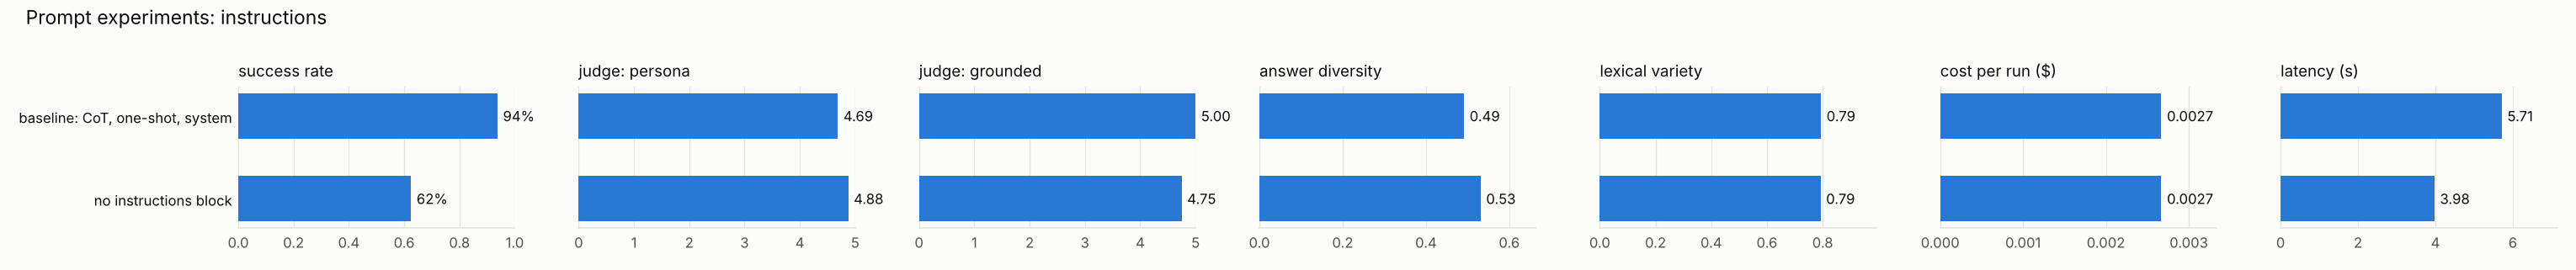

In [23]:
display(report.table("prompt", "instructions"))
display(Image(filename=str(report.chart_path("prompt", "instructions"))))

Removing the instructions block is the largest effect in the whole study: **success drops
from 94% to 62%**, and each failure maps to a missing rule (section 7, question 4).

### 6.3 Configuration
First, what each model accepts. This table is measured, not assumed: `scripts/probe_models.py` sends every setting to
every model. Two findings shaped the personas: **top-k does not exist** in the OpenAI API, and on the newer models
**sampling settings only work with `reasoning_effort="none"`**.

In [24]:
report.capability_table()

,gpt-6-luna,gpt-5.4-mini,gpt-5.4-nano,gpt-6.1-sol,gpt-4.1-mini,gpt-4o-mini
temperature=0.2,no,yes,yes,no,yes,yes
temperature=1.2,no,yes,yes,no,yes,yes
top_p=0.5,no,yes,yes,no,yes,yes
frequency_penalty=0.6,no,yes,yes,no,yes,yes
presence_penalty=0.6,no,yes,yes,no,yes,yes
max_completion_tokens=20,yes,yes,yes,yes,yes,yes
max_tokens=20,no,no,no,no,yes,yes
stop=['Observation:'],no,no,no,no,yes,yes
seed=7,yes,yes,yes,yes,yes,yes
reasoning_effort=none,yes,yes,yes,no,no,no


**Temperature**

setup,runs,success rate,judge: persona,answer diversity,same numbers every time,words,lexical variety,repeated trigrams
temperature 0.0,9,100%,4.33,0.64,67%,173,0.65,0.05
temperature 0.6,9,100%,4.56,0.67,67%,155,0.68,0.04
temperature 1.1,9,100%,4.67,0.68,67%,173,0.68,0.05
temperature 1.6,9,100%,4.67,0.62,33%,163,0.67,0.05


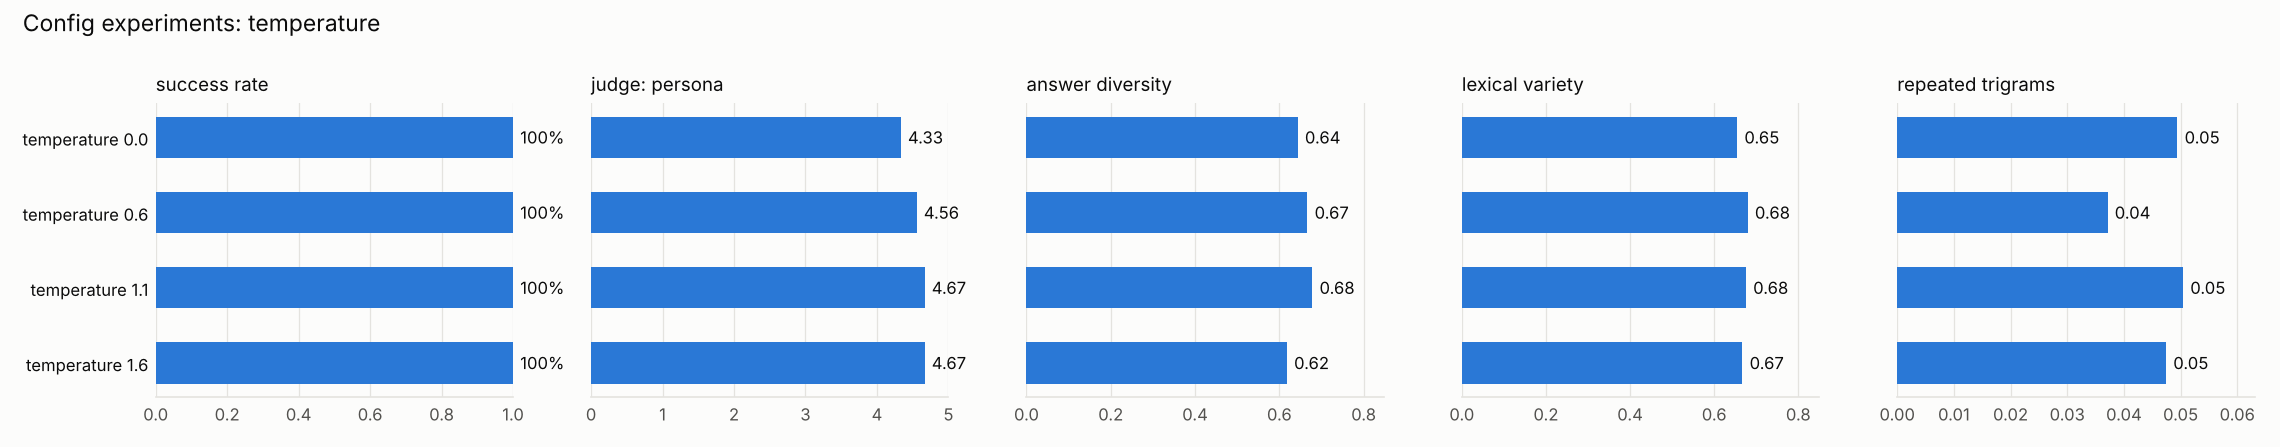

In [25]:
display(report.table("config", "temperature"))
display(Image(filename=str(report.chart_path("config", "temperature"))))

Temperature (0 → 1.6, three repeats each, on Rami's budget question and Layla's two
descriptions): **success stayed at 100%** and the judge's persona score rose slightly with temperature (4.33 → 4.67).
At 1.6, only 33% of tasks gave the same numbers in all three repeats, against 67% at lower temperatures: higher
temperature changes which figures the agent chooses to mention, not the totals (T01's $345 was right in every run).

**Top_p**

setup,runs,success rate,judge: persona,answer diversity,words,lexical variety,repeated trigrams
top_p 0.3,4,100%,5.00,0.74,184,0.65,0.05
top_p 0.7,4,100%,4.75,0.77,197,0.64,0.05
top_p 1.0,4,100%,5.00,0.68,218,0.65,0.06


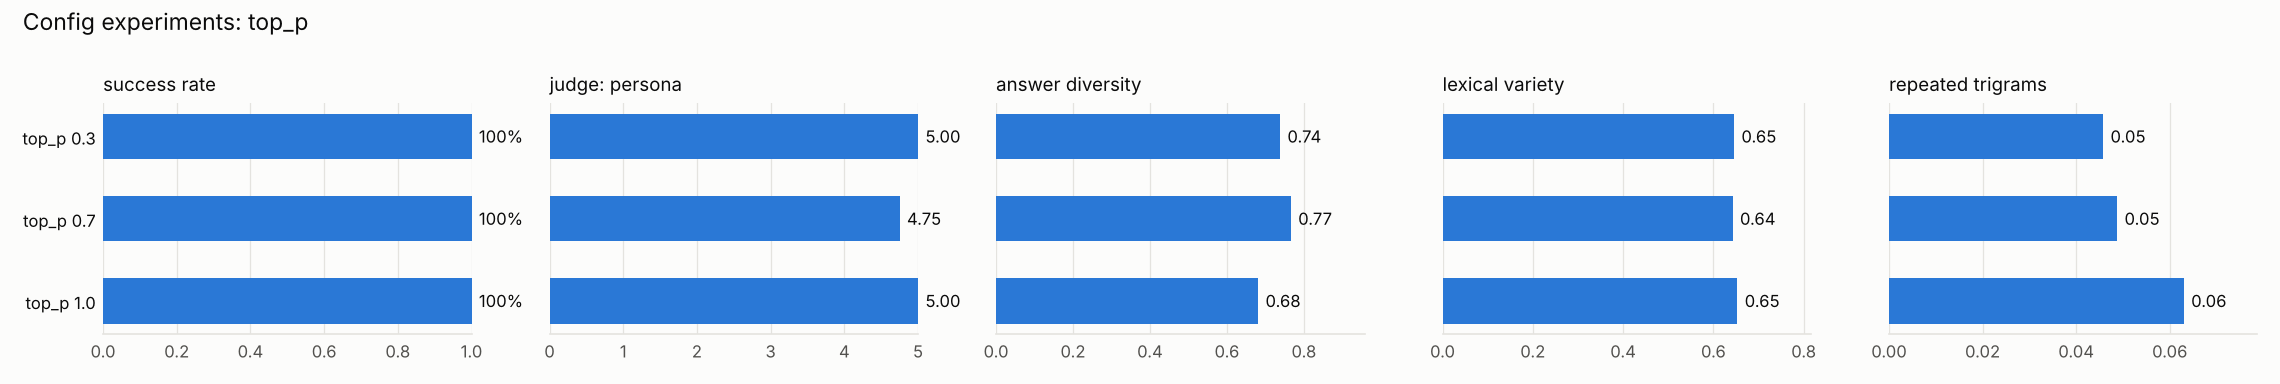

In [26]:
display(report.table("config", "top_p"))
display(Image(filename=str(report.chart_path("config", "top_p"))))

top-p on Layla: all variants succeed; lower top-p gives shorter answers (184 vs 218 words) with less
repetition. The effect is smaller than temperature's.

**Penalties**

setup,runs,success rate,judge: persona,answer diversity,words,lexical variety,repeated trigrams
no penalties,4,100%,5.00,0.73,235,0.63,0.09
Layla's penalties (0.6 / 0.3),4,100%,4.00,0.80,212,0.63,0.05
high penalties (1.5 / 1.0),4,100%,4.50,0.78,160,0.72,0.02


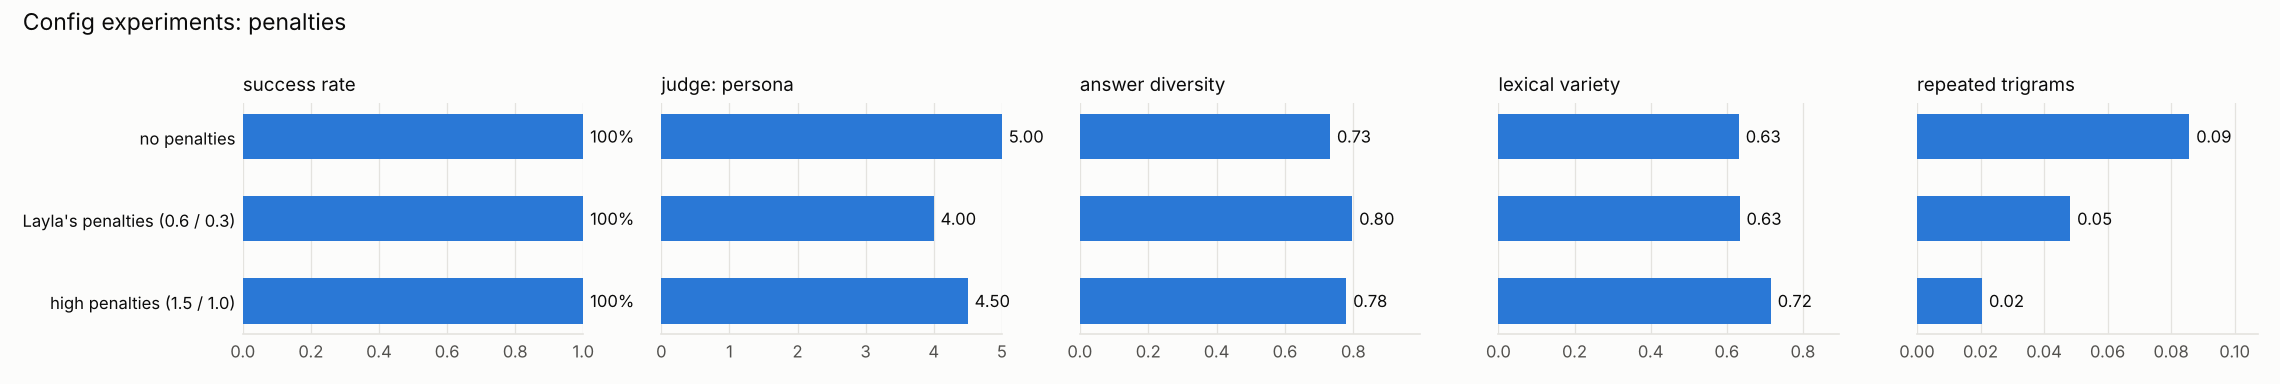

In [27]:
display(report.table("config", "penalties"))
display(Image(filename=str(report.chart_path("config", "penalties"))))

The clearest sampling effect: **repeated three-word phrases fall from 8.6% with no penalties to
4.8% with Layla's settings and 2.0% with high penalties**, and answers get shorter. High penalties also cost a little
helpfulness and grounding (4.75), so Layla's moderate values are the balance.

**Max tokens**

setup,runs,success rate,judge: helpful,judge: persona,cut off by max tokens,words,cost per run ($)
max_completion_tokens 150,3,100%,2.33,3.67,3,67,$0.0029
max_completion_tokens 400,3,100%,5.00,4.00,0,130,$0.0034
max_completion_tokens 900,3,100%,5.00,4.33,0,126,$0.0039


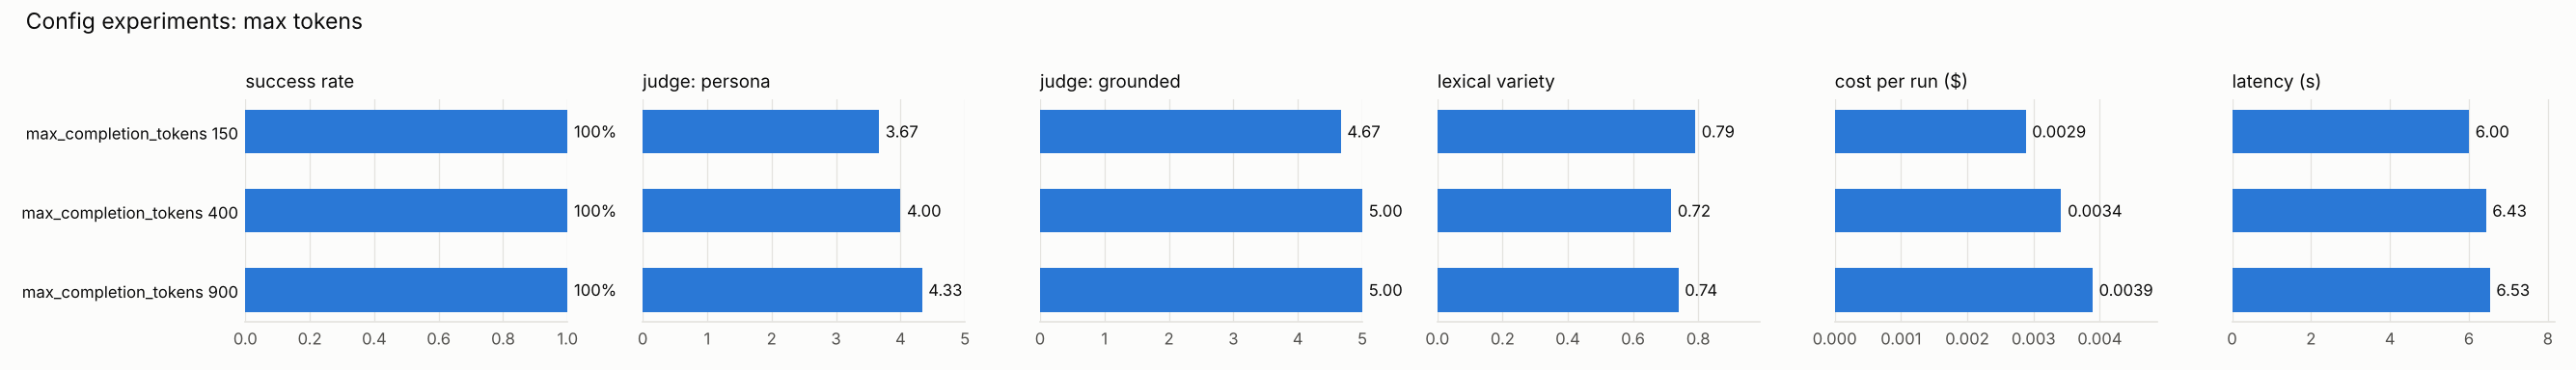

In [28]:
display(report.table("config", "max tokens"))
display(Image(filename=str(report.chart_path("config", "max tokens"))))

A 150-token limit cut off **all three** answers mid-sentence: helpfulness fell from 5.0 to 2.3,
even though the checks still passed (the key numbers came early). 400 tokens was already enough here; the personas use
500–900 to leave room for a ReAct step plus the answer.

**Model**

setup,runs,success rate,judge: persona,judge: helpful,judge: grounded,model calls,format slips,words,cost per run ($),latency (s)
gpt-5.4-nano,6,83%,5.00,4.83,5.00,2.17,0,65,$0.0010,3.8
gpt-5.4-mini,6,83%,4.83,4.83,4.83,2.83,1,78,$0.0035,4.6
gpt-6-luna,6,83%,4.67,4.67,5.00,2.83,1,50,$0.0005,5.5
gpt-4.1-mini,6,83%,4.83,4.83,5.00,2.33,1,69,$0.0023,3.1
gpt-4o-mini,6,50%,4.33,4.33,4.67,1.83,4,73,$0.0009,2.7
gpt-6.1-sol,6,83%,4.83,4.83,4.83,2.50,0,64,$0.0091,12.8


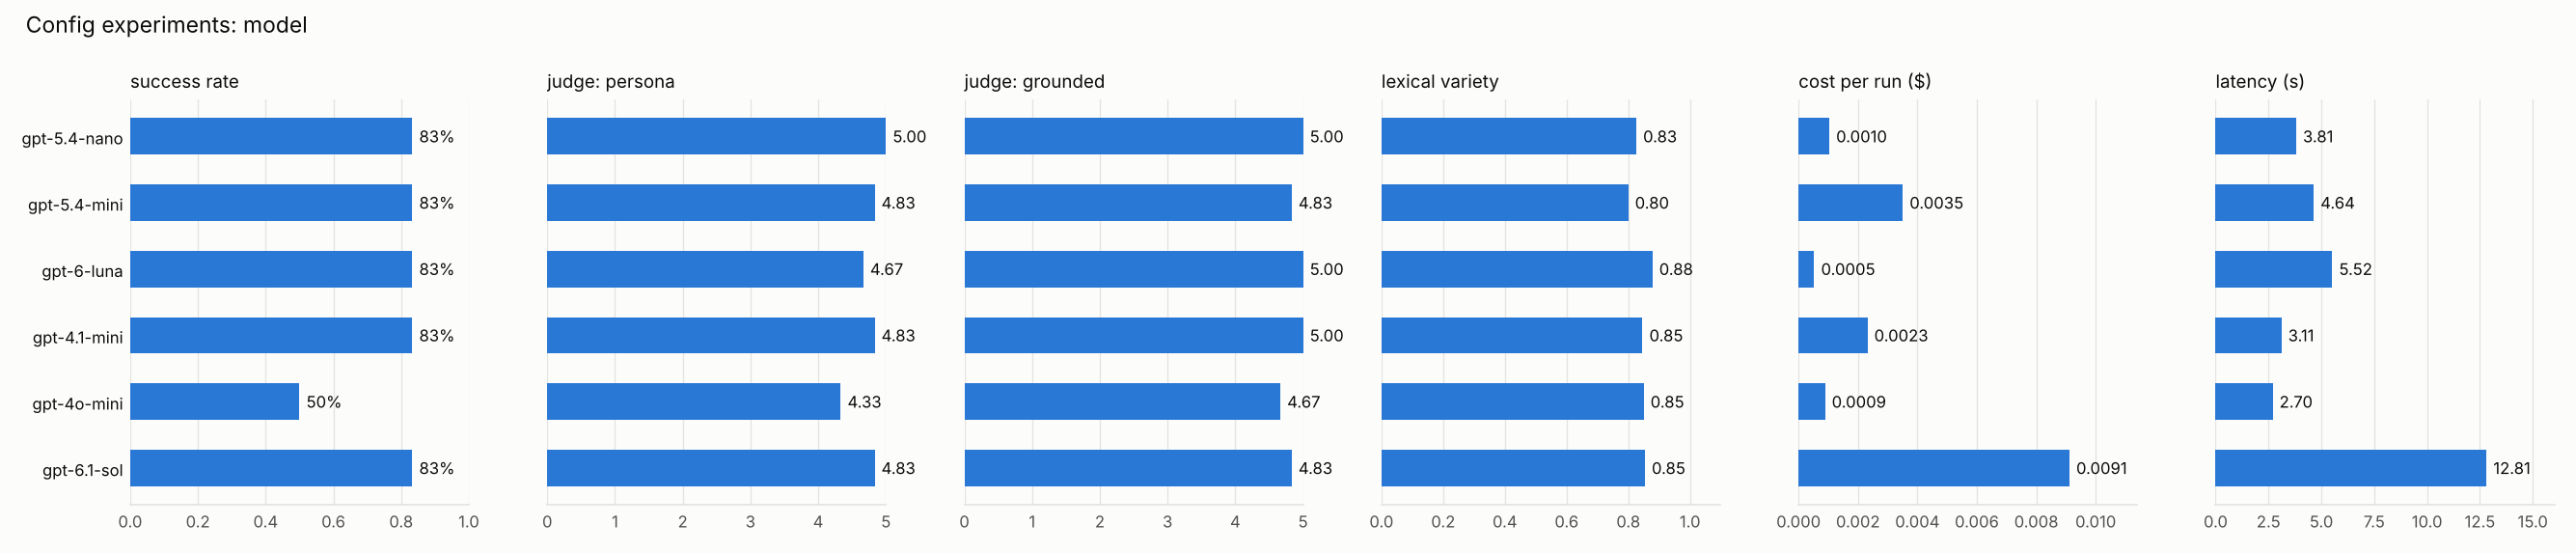

In [29]:
display(report.table("config", "model"))
display(Image(filename=str(report.chart_path("config", "model"))))

Six models on the same tasks with the same prompt. **gpt-5.4-nano matches gpt-5.4-mini at about a
third of the cost**; gpt-6-luna is the cheapest and the tersest; **gpt-4o-mini is the weakest (50%)**, answering from
general knowledge instead of using tools; gpt-6.1-sol costs 2.6× mini and is almost 3× slower for no gain.

**Reasoning effort**

setup,runs,success rate,judge: helpful,model calls,output tokens,cost per run ($),latency (s)
effort none (sampling sent),4,100%,5.00,2.75,282,$0.0027,4.4
effort low (sampling dropped),4,100%,5.00,3.50,487,$0.0075,6.5


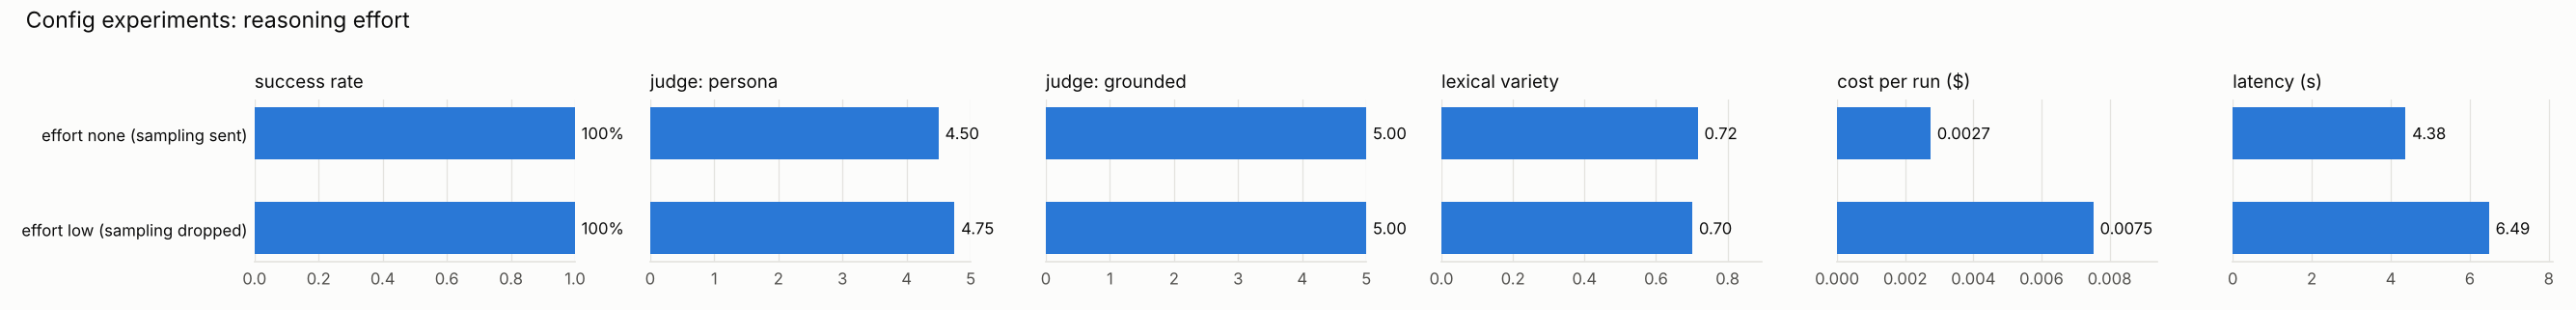

In [30]:
display(report.table("config", "reasoning effort"))
display(Image(filename=str(report.chart_path("config", "reasoning effort"))))

Rami's configuration question, measured: effort `low` gives the same success but uses
**1.7× the output tokens, 2.8× the cost and 2 s more**, and (as the probe predicted) the temperature and top-p
settings were dropped. Effort `none` with precise sampling is the better choice for this agent.

**Stop sequence**

setup,runs,success rate,invented observations,format errors,format slips,cost per run ($)
"gpt-4.1-mini, parser only",4,75%,0,0,0,$0.0017
gpt-4.1-mini + stop 'Observation:',4,75%,0,0,0,$0.0022


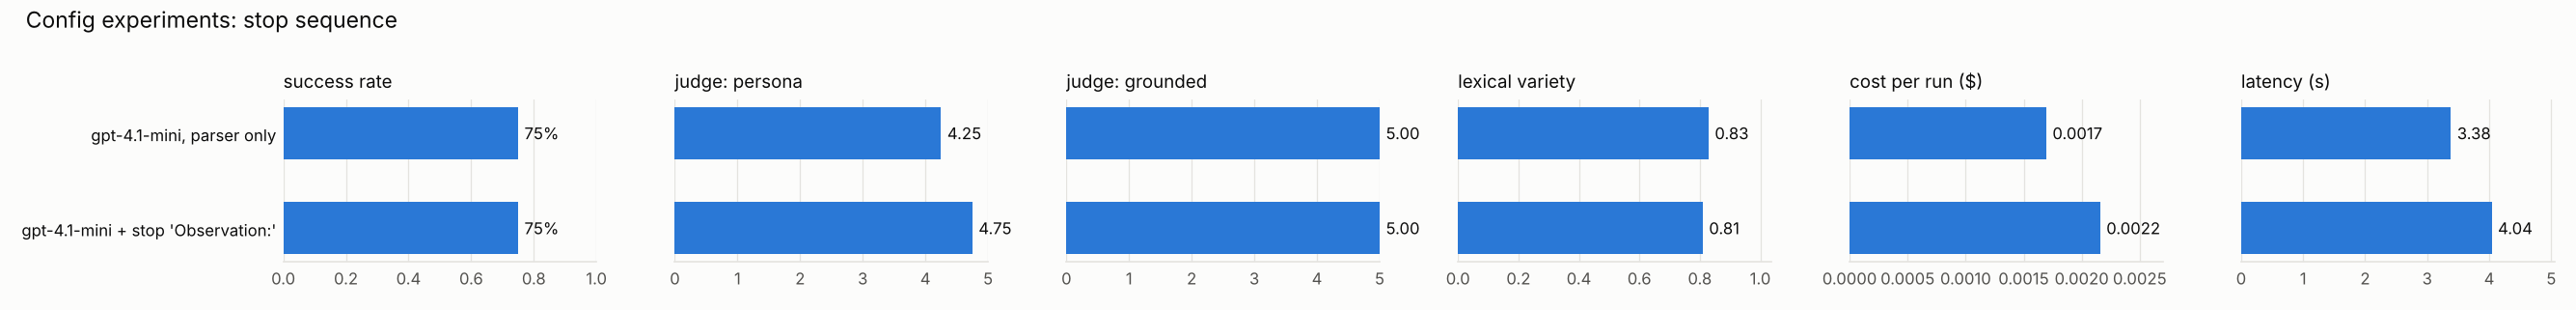

In [31]:
display(report.table("config", "stop sequence"))
display(Image(filename=str(report.chart_path("config", "stop sequence"))))

On gpt-4.1-mini (one of the few models that accepts `stop`): **no invented observations
either way**. Across all 297 runs, no model ever wrote its own Observation, so the parser's cut-off is a safety net
rather than a necessity for these models.

### 6.4 Closing the loop: instructions v1 → v2
Two failures kept appearing in every suite:
- **T07** (*"Is D10 wheelchair accessible?"*): the question was logged but the visitor was rarely given the reference.
  The rules said *when* a reference may be quoted, never that it should be.
- **T19** (a booking spread over two messages): with the experience, name and email all known, the agent asked for a
  date instead of saving the inquiry. Nothing said a date was optional.

Version 2 adds one single-purpose rule for each (section 4). Same tasks, three repeats each, plus two lead and
feedback tasks to check nothing else got worse:

In [32]:
display(report.table("iteration", "rules version"))
runs = report.ex.load_runs("iteration")
display(runs.pivot_table(index="task", columns="arm", values="success", aggfunc="sum")
        .rename_axis(columns=None).astype(int).astype(str).add(" / 3"))

setup,runs,success rate,checks passed,judge: persona,judge: helpful,judge: grounded,model calls,cost per run ($)
instructions v1 (first version),12,58%,91%,4.75,4.50,4.67,1.92,$0.0012
instructions v2 (+2 rules),12,92%,99%,4.83,4.67,5.00,2.08,$0.0014


,instructions v1 (first version),instructions v2 (+2 rules)
task,,
T07,0 / 3,2 / 3
T09,3 / 3,3 / 3
T16,3 / 3,3 / 3
T19,1 / 3,3 / 3


**Success went from 58% to 92%**: T07 from 0/3 to 2/3, T19 from 1/3 to 3/3, and the two control tasks stayed at 3/3.
The one remaining failure gave the reference but forgot to say the information is not documented.

### 6.5 The best combination for this use case
| choice | best setting | evidence |
|---|---|---|
| personas | **Auto mode** with four personas | right persona 100% of the time; Nadia logs feedback the generalist skipped |
| reasoning style | **chain of thought** (Thought lines) | same success, 5× fewer format slips |
| examples | **few-shot** | the only 100% variant; examples teach behaviours the rules do not state |
| instructions | **v2 rules**, block kept | 62% without the block; 58% → 92% from v1 to v2 on the targeted tasks |
| placement | system prompt (in-message is a strong alternative) | in-message was faster with fewer calls at equal success |
| model | **gpt-5.4-mini**, **nano** for Nadia | nano matches mini at a third of the cost; 4o-mini fails half the tasks |
| effort | **none**, with per-persona sampling | `low` costs 2.8× and drops temperature/top-p |
| penalties | moderate for Layla only | repetition 8.6% → 4.8% without losing quality |
| max tokens | ≥ 400 | 150 cut every answer |

## 7. Reflection

### Which persona gave the most helpful or natural results?
**Alaa, the warm host, was the most natural**: a perfect 5/5 fidelity score on every question she was given, short
friendly answers, and on her own she passed 95% of the full test set. But "most helpful" depended on the task, and
that is the case for personas with different jobs. **Rami** was the most trustworthy for numbers: he always showed the
calculation, and the budget total was right in all 43 runs of that task. **Nadia** was the one who reliably logged
praise and undocumented questions; Alaa, as a generalist, thanked a visitor for praise but did not log it, in both runs.
**Layla** was the least natural at first: her early answers were one vivid sentence followed by a fact sheet, and she
was by far the persona most tempted to describe places from the background text without searching the catalog (91% of
her first drafts were sent back by the grounding check, against 4% for Rami). Her penalties do their job, though:
they cut repeated phrases roughly in half (section 6.3).

### Which prompt and configuration combination performed best?
Chain of thought + few-shot examples + the v2 instructions block in the system prompt, with each persona on
`reasoning_effort="none"` so its sampling settings actually apply, gpt-5.4-mini for the three main personas and nano
for the guardian (table 6.5). Two surprises: **temperature barely affected correctness** (100% at every value from 0
to 1.6; it changed wording and which numbers were mentioned), and **reasoning effort `low` was strictly worse here**,
costing 2.8× for the same success while silently disabling temperature and top-p.

### How well did the agent reason and use tools?
Well, with two clear patterns. Across 297 runs every turn ended with an answer, the right tool was used for every
total (`budget_calculator` 43 times on the budget task, always $345), and no model ever invented an observation.
Format errors were rare (8 in 297 runs) and always recovered. The weak spot was **grounding**: the business summary in
the prompt already lists prices and seasons, so in **45% of runs the first draft answered from it before calling a
tool**, and the grounding check sent it back (92% of those runs then succeeded). The other weakness was over-caution:
asking for details it did not need (a date for an inquiry) instead of acting. Model choice mattered most for tool use:
gpt-4o-mini skipped tools and answered from general knowledge.

### Did the instructions block change the agent's behaviour? How?
Yes, more than any other change. Without it, success fell from 94% to 62%, and every failure maps to a rule that was
missing: Rami gave the correct total but **skipped the season check** ("check the season before suggesting a month"),
the March 5 answer **never said which year** ("a date without a year means the next one; state the year"), and Nadia
once **did not log** an undocumented accessibility question ("log questions the documents cannot answer"). Format
slips also rose from 2 to 12, because the block carries the output format. The block was improved the same way: two
rules written from observed failures raised success on those tasks from 58% to 92% (section 6.4).

### What were the biggest challenges?
1. **The API is not uniform across models.** top-k does not exist; newer models reject `stop` and `max_tokens`; and
   sampling settings are rejected whenever reasoning effort is above `none`. Rami's first configuration would have
   silently lost its temperature. I solved it by probing every model and making the code drop and report unsupported
   settings, plus a test that fails if any persona's setting would be dropped.
2. **Parsing free text robustly.** Without a stop sequence the parser must handle bold labels, fences, inline calls,
   plain answers, and invented observations, and send real format errors back as observations.
3. **A fix that backfired.** The first grounding check was read by the model as the visitor speaking ("You're right,
   I should check..."), and it then stopped without checking. Rewording it as an internal system check that must be
   followed by an action fixed it.
4. **Evaluating the evaluator.** Two early "agent failures" were mine: a check that accepted "not documented" but not
   "isn't documented", and a judge that saw only the first 1,500 characters of a tool result and marked correct facts
   as invented. Reading the actual answers behind every failure before trusting a number was the most useful habit.
5. **Small samples.** With 8–20 runs per variant, one task moves a success rate by 5–12 points, so I repeated runs,
   reported the per-task evidence, and treated small differences (like Auto 90% vs host 95%) as noise.

## 8. Limitations and next steps
- **Sample sizes are small** (4–20 runs per variant); the large effects (no instructions, 150 tokens, gpt-4o-mini,
  v1 → v2) are clear, the small ones are not.
- **The judge is generous and related to the agent** (gpt-5.4-mini judges gpt-5.4-mini): scores cluster at 4.5–5.
  A judge from another model family and blind pairwise comparisons would separate variants better.
- **Grounding costs an extra call in 45% of runs.** A next step is to keep prices out of the business summary so the
  model must call a tool, and measure whether that removes the extra step.
- **Auto mode uses rules** to pick the persona; an LLM classifier would handle phrasings the patterns miss.
- **Next:** the Gradio app (`app.py`) exposes the persona picker, Auto mode, and the ReAct trace for every answer.